
# RQ17 — Robustness: what does it really mean to “win”?

## Scientific question

**Across the complete supervised benchmark, does the identity of the “best” model depend on whether winning is defined by peak performance, average performance, worst-case performance, rank consistency, regret, or sensitivity to the R×S generalization landscape?**

RQ17 is a **synthesis analysis**. It does not train models, regenerate predictions, or bootstrap uncertainty.

The unit analyzed here is a complete:

`task × representation × algorithm`

model surface evaluated over the 16 native `R × S` cells.

### Roadmap contract

For each surface, RQ17 quantifies:

| Concept | Definition |
|---|---|
| Peak | best MCC over the 16 R×S cells |
| Average | mean MCC over the 16 cells |
| Median | median MCC over the 16 cells |
| Worst case | minimum MCC over the 16 cells |
| Range | maximum − minimum MCC |
| Win count | number of R×S cells won within the same task |
| Mean rank | average rank across the 16 cells |
| Worst rank | worst rank reached across the 16 cells |
| Regret | distance from the best strategy in each matched task×R×S cell |
| R sensitivity | median absolute extreme R effect across fixed S |
| S sensitivity | median absolute extreme S effect across fixed R |
| Interaction sensitivity | RMS non-additive residual of the full R×S surface |

The objective is deliberately **not** to force one universal winner. Instead, RQ17 asks whether we obtain different winners under different operational meanings of robustness.



## Interpretation contract

- MCC is the primary metric.
- Rankings and regret are calculated **only within the same `task × R × S` cell**, where all 20 `representation × algorithm` strategies are directly comparable.
- Raw MCC values from biologically different tasks are not treated as paired observations.
- Cross-task summaries use **within-task ranks/regrets** whenever possible.
- `R` sensitivity uses the same extreme-span definition as RQ5:

\[
E_R = \mathrm{median}_{S}\left|M(R30,S)-M(R90,S)\right|.
\]

- `S` sensitivity is:

\[
E_S = \mathrm{median}_{R}\left|M(R,S30)-M(R,S90)\right|.
\]

- Interaction sensitivity uses the RQ4 factorial additive residual:

\[
I_{\mathrm{RMS}}
=
\sqrt{\mathrm{mean}\left[(M-\widehat{M}_{add})^2\right]}.
\]

- Sensitivity alone cannot define a useful model: a consistently poor model can be perfectly “stable”. Whenever RQ17 identifies the **least sensitive competitive model**, competition is restricted to strategies whose mean MCC lies within `0.02` of the best mean MCC for that task. This is a descriptive deployment guardrail, **not an equivalence margin**.
- Bootstrap uncertainty belongs to RQ19 and is not repeated here.
- Compute efficiency belongs to RQ23/RQ26 and is not redefined here.


In [1]:

from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 400)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]
PRIMARY_METRIC = "mcc"
COMPETITIVE_GAP = 0.02
NEAR_BEST_GAP = 0.01

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

REP_ORDER = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

ALG_ORDER = ["KNN", "LR", "MLP", "RF", "XGB"]

REP_LABEL = {
    "roxy_48": "Roxy",
    "onehot_1024": "One-hot",
    "esm2_t6_8m": "ESM2-T6",
    "esm2_t30_150m": "ESM2-T30",
}

TASK_LABEL = {
    "global_easy": "Global easy",
    "global_hard": "Global hard",
    "global_mixed": "Global mixed",
    "subtype_endolysin": "Endolysin",
    "subtype_depolymerase": "Depolymerase",
    "subtype_val": "VAL",
    "multiclass_clean": "Multiclass",
}


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        master = candidate / "results/analysis_supervised/stage12a/supervised_master_results.tsv"
        if master.is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the PhageLysClass project root containing "
        "results/analysis_supervised/stage12a/supervised_master_results.tsv"
    )


ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
CACHE_ROOT = ROOT / "results/analysis_supervised/notebook_cache"
RQ6_DIR = CACHE_ROOT / "rq6_surface_geometry"
RQ17_OUT = CACHE_ROOT / "rq17_robustness_synthesis"
FIG_DIR = RQ17_OUT / "figures"

RQ17_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ17_OUT:", RQ17_OUT)
print("No model training, prediction regeneration, or bootstrap is performed in RQ17.")


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ17_OUT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq17_robustness_synthesis
No model training, prediction regeneration, or bootstrap is performed in RQ17.


## 1. Load and validate the frozen supervised benchmark

In [2]:

master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

required = {"task", "R", "S", "representation", "algorithm", PRIMARY_METRIC}
missing = required - set(master.columns)
if missing:
    raise KeyError(f"supervised_master_results.tsv missing required columns: {sorted(missing)}")

for c in ["R", "S", PRIMARY_METRIC]:
    master[c] = pd.to_numeric(master[c], errors="coerce")

if master[["R", "S", PRIMARY_METRIC]].isna().any().any():
    raise ValueError("R, S, or MCC contains non-numeric / missing values.")

master["R"] = master["R"].astype(int)
master["S"] = master["S"].astype(int)

observed_tasks = list(master["task"].dropna().astype(str).unique())
observed_reps = list(master["representation"].dropna().astype(str).unique())
observed_algs = list(master["algorithm"].dropna().astype(str).unique())

TASKS = [x for x in TASK_ORDER if x in observed_tasks] + sorted(set(observed_tasks) - set(TASK_ORDER))
REPS = [x for x in REP_ORDER if x in observed_reps] + sorted(set(observed_reps) - set(REP_ORDER))
ALGS = [x for x in ALG_ORDER if x in observed_algs] + sorted(set(observed_algs) - set(ALG_ORDER))

assert set(master["R"].unique()) == set(R_LEVELS), f"Unexpected R levels: {sorted(master['R'].unique())}"
assert set(master["S"].unique()) == set(S_LEVELS), f"Unexpected S levels: {sorted(master['S'].unique())}"

key_cols = ["task", "R", "S", "representation", "algorithm"]
if master.duplicated(key_cols).any():
    dup = master.loc[master.duplicated(key_cols, keep=False), key_cols].sort_values(key_cols)
    raise ValueError("Duplicate supervised cells detected:\n" + dup.head(30).to_string(index=False))

n_expected_strategies = len(REPS) * len(ALGS)
n_expected_task_cells = len(TASKS) * len(R_LEVELS) * len(S_LEVELS)
n_expected_rows = n_expected_task_cells * n_expected_strategies
n_expected_surfaces = len(TASKS) * n_expected_strategies

coverage_cells = (
    master.groupby(["task", "R", "S"], as_index=False)
    .agg(
        n_strategies=(PRIMARY_METRIC, "size"),
        n_representations=("representation", "nunique"),
        n_algorithms=("algorithm", "nunique"),
    )
)

coverage_surfaces = (
    master.groupby(["task", "representation", "algorithm"], as_index=False)
    .agg(
        n_cells=(PRIMARY_METRIC, "size"),
        n_R=("R", "nunique"),
        n_S=("S", "nunique"),
    )
)

print("Rows:", len(master), "/ expected", n_expected_rows)
print("Task×R×S comparison cells:", len(coverage_cells), "/ expected", n_expected_task_cells)
print("Complete model surfaces:", len(coverage_surfaces), "/ expected", n_expected_surfaces)
print("Strategies per task cell:", n_expected_strategies)
print("Tasks:", TASKS)
print("Representations:", REPS)
print("Algorithms:", ALGS)

assert len(master) == n_expected_rows
assert len(coverage_cells) == n_expected_task_cells
assert coverage_cells["n_strategies"].eq(n_expected_strategies).all()
assert coverage_cells["n_representations"].eq(len(REPS)).all()
assert coverage_cells["n_algorithms"].eq(len(ALGS)).all()
assert len(coverage_surfaces) == n_expected_surfaces
assert coverage_surfaces["n_cells"].eq(16).all()
assert coverage_surfaces["n_R"].eq(4).all()
assert coverage_surfaces["n_S"].eq(4).all()

master["strategy_id"] = master["representation"].astype(str) + " + " + master["algorithm"].astype(str)

print("FACTORIAL_COVERAGE_OK")


Rows: 2240 / expected 2240
Task×R×S comparison cells: 112 / expected 112
Complete model surfaces: 140 / expected 140
Strategies per task cell: 20
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'subtype_endolysin', 'subtype_depolymerase', 'subtype_val', 'multiclass_clean']
Representations: ['roxy_48', 'onehot_1024', 'esm2_t6_8m', 'esm2_t30_150m']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']
FACTORIAL_COVERAGE_OK



## 2. Reuse the completed RQ6 surface summary

RQ6 is the canonical source for whole-surface performance geometry (`peak`, `mean`, `median`, `worst`, `range`, strict-corner performance and roughness). RQ17 consumes that output instead of rebuilding it.

If the RQ6 cache is absent, execution stops: RQ17 should not silently bypass a required completed analysis.


In [3]:

rq6_surface_path = RQ6_DIR / "rq6_surface_summary.tsv"

if not rq6_surface_path.is_file():
    raise FileNotFoundError(
        f"RQ6 canonical surface summary not found: {rq6_surface_path}. "
        "Execute the completed RQ6 notebook first."
    )

rq6 = pd.read_csv(rq6_surface_path, sep="\t", low_memory=False)

rq6_required = {
    "task", "representation", "algorithm",
    "mean_mcc", "median_mcc", "worst_mcc", "best_mcc", "surface_range",
    "baseline_mcc_R90S90", "strict_mcc_R30S30", "strict_delta",
    "strict_retention_fraction", "mean_adjacent_abs_change",
}
rq6_missing = rq6_required - set(rq6.columns)
if rq6_missing:
    raise KeyError(f"RQ6 surface summary missing required columns: {sorted(rq6_missing)}")

assert len(rq6) == n_expected_surfaces
assert not rq6.duplicated(["task", "representation", "algorithm"]).any()

surface = rq6.copy()
surface["strategy_id"] = surface["representation"].astype(str) + " + " + surface["algorithm"].astype(str)
surface = surface.rename(columns={"best_mcc": "peak_mcc"})

print("RQ6 surfaces loaded:", len(surface))
display(
    surface[
        [
            "task", "representation", "algorithm",
            "peak_mcc", "mean_mcc", "median_mcc",
            "worst_mcc", "surface_range",
            "strict_mcc_R30S30", "strict_delta",
        ]
    ].head()
)


RQ6 surfaces loaded: 140


,task,representation,algorithm,peak_mcc,mean_mcc,median_mcc,worst_mcc,surface_range,strict_mcc_R30S30,strict_delta
0,global_easy,roxy_48,LR,0.511638,0.482347,0.479575,0.449463,0.062175,0.473778,-0.037860
1,global_easy,roxy_48,RF,0.710186,0.630261,0.625915,0.537101,0.173086,0.537101,-0.171429
2,global_easy,roxy_48,KNN,0.770957,0.653812,0.652242,0.569305,0.201651,0.569305,-0.201651
3,global_easy,roxy_48,XGB,0.772730,0.690156,0.687379,0.591684,0.181046,0.640564,-0.132166
4,global_easy,roxy_48,MLP,0.774161,0.670811,0.651686,0.597200,0.176961,0.633651,-0.140511



## 3. Cell-wise competition: wins, ranks and regret

Within every matched `task × R × S` cell:

- rank 1 = highest MCC;
- exact win count = number of cells with rank 1;
- near-best count = number of cells within `0.01 MCC` of the cell winner;
- regret = `best MCC in the cell − strategy MCC`.

This makes “winning” comparable across tasks without pooling their raw MCC scales.


In [4]:

cell_rankings = master.copy()

group_cell = ["task", "R", "S"]

cell_rankings["cell_best_mcc"] = (
    cell_rankings.groupby(group_cell)[PRIMARY_METRIC].transform("max")
)
cell_rankings["cell_regret"] = cell_rankings["cell_best_mcc"] - cell_rankings[PRIMARY_METRIC]
cell_rankings["cell_rank"] = (
    cell_rankings.groupby(group_cell)[PRIMARY_METRIC]
    .rank(method="min", ascending=False)
)
cell_rankings["exact_win"] = cell_rankings["cell_rank"].eq(1.0)
cell_rankings["near_best_001"] = cell_rankings["cell_regret"].le(NEAR_BEST_GAP + 1e-12)

assert len(cell_rankings) == len(master)
assert (cell_rankings["cell_regret"] >= -1e-12).all()
assert cell_rankings.groupby(group_cell)["cell_rank"].min().eq(1.0).all()
assert cell_rankings.groupby(group_cell)["exact_win"].sum().ge(1).all()

rank_summary = (
    cell_rankings.groupby(["task", "representation", "algorithm", "strategy_id"], as_index=False)
    .agg(
        win_count=("exact_win", "sum"),
        near_best_count_001=("near_best_001", "sum"),
        mean_rank=("cell_rank", "mean"),
        median_rank=("cell_rank", "median"),
        worst_rank=("cell_rank", "max"),
        best_rank=("cell_rank", "min"),
        mean_regret=("cell_regret", "mean"),
        median_regret=("cell_regret", "median"),
        worst_regret=("cell_regret", "max"),
        q75_regret=("cell_regret", lambda x: x.quantile(0.75)),
    )
)

assert len(rank_summary) == n_expected_surfaces
assert rank_summary["win_count"].between(0, 16).all()
assert rank_summary["near_best_count_001"].between(0, 16).all()

display(
    rank_summary.sort_values(["task", "mean_rank", "mean_regret"]).head(30)
)


,task,representation,algorithm,strategy_id,win_count,near_best_count_001,mean_rank,median_rank,worst_rank,best_rank,mean_regret,median_regret,worst_regret,q75_regret
0,global_easy,esm2_t30_150m,KNN,esm2_t30_150m + KNN,9,15,1.5625,1.0,3.0,1.0,0.002340,0.000000,0.012738,0.001955
2,global_easy,esm2_t30_150m,MLP,esm2_t30_150m + MLP,6,12,1.8125,2.0,3.0,1.0,0.005582,0.003133,0.020904,0.007869
4,global_easy,esm2_t30_150m,XGB,esm2_t30_150m + XGB,1,6,2.6250,3.0,3.0,1.0,0.011238,0.011294,0.025633,0.012678
1,global_easy,esm2_t30_150m,LR,esm2_t30_150m + LR,0,0,4.3125,4.0,5.0,4.0,0.041490,0.038935,0.072587,0.047329
3,global_easy,esm2_t30_150m,RF,esm2_t30_150m + RF,0,0,4.6875,5.0,5.0,4.0,0.047701,0.053154,0.069746,0.059819
7,global_easy,esm2_t6_8m,MLP,esm2_t6_8m + MLP,0,0,6.3750,6.0,8.0,6.0,0.092178,0.087074,0.134275,0.109848
9,global_easy,esm2_t6_8m,XGB,esm2_t6_8m + XGB,0,0,7.1250,7.0,8.0,6.0,0.104115,0.105141,0.141670,0.114106
5,global_easy,esm2_t6_8m,KNN,esm2_t6_8m + KNN,0,0,7.5000,8.0,8.0,6.0,0.109663,0.118306,0.134926,0.123206
8,global_easy,esm2_t6_8m,RF,esm2_t6_8m + RF,0,0,9.1250,9.0,10.0,9.0,0.170620,0.176212,0.199153,0.184802
6,global_easy,esm2_t6_8m,LR,esm2_t6_8m + LR,0,0,9.8750,10.0,10.0,9.0,0.200290,0.195613,0.227923,0.215386


## 4. R sensitivity, S sensitivity and non-additive interaction sensitivity

In [5]:

def derive_sensitivity_from_master(df):
    rows = []
    for keys, grp in df.groupby(["task", "representation", "algorithm"], sort=False):
        task, rep, alg = keys
        mat = (
            grp.pivot(index="R", columns="S", values=PRIMARY_METRIC)
            .reindex(index=R_LEVELS, columns=S_LEVELS)
        )
        if mat.isna().any().any():
            raise ValueError(f"Incomplete R×S surface for {keys}")

        r_effects = np.array(
            [float(mat.loc[30, s] - mat.loc[90, s]) for s in S_LEVELS],
            dtype=float,
        )
        s_effects = np.array(
            [float(mat.loc[r, 30] - mat.loc[r, 90]) for r in R_LEVELS],
            dtype=float,
        )

        matrix = mat.to_numpy(dtype=float)
        grand = matrix.mean()
        r_main = matrix.mean(axis=1) - grand
        s_main = matrix.mean(axis=0) - grand
        additive = grand + r_main[:, None] + s_main[None, :]
        residual = matrix - additive

        ss_r = len(S_LEVELS) * np.sum(r_main ** 2)
        ss_s = len(R_LEVELS) * np.sum(s_main ** 2)
        ss_int = np.sum(residual ** 2)
        ss_total = np.sum((matrix - grand) ** 2)

        rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "R_sensitivity_abs_median": float(np.median(np.abs(r_effects))),
                "S_sensitivity_abs_median": float(np.median(np.abs(s_effects))),
                "R_effect_signed_median": float(np.median(r_effects)),
                "S_effect_signed_median": float(np.median(s_effects)),
                "interaction_rms": float(np.sqrt(np.mean(residual ** 2))),
                "interaction_fraction": float(ss_int / ss_total) if ss_total > 0 else np.nan,
                "R_fraction": float(ss_r / ss_total) if ss_total > 0 else np.nan,
                "S_fraction": float(ss_s / ss_total) if ss_total > 0 else np.nan,
            }
        )
    return pd.DataFrame(rows)


derived_sensitivity = derive_sensitivity_from_master(master)
assert len(derived_sensitivity) == n_expected_surfaces

# Prefer canonical RQ5/RQ4 outputs when available, and verify that they agree
# with the direct derivation used as a reproducibility check.
rq5_path = CACHE_ROOT / "rq5_surface_dominance.tsv"
rq4_path = CACHE_ROOT / "rq4_factorial_decomposition.tsv"

sensitivity = derived_sensitivity.copy()
sources_used = ["direct_stage12a_reproducibility_check"]

if rq5_path.is_file():
    rq5 = pd.read_csv(rq5_path, sep="\t", low_memory=False)
    rq5_keep = rq5[
        [
            "task", "representation", "algorithm",
            "R_effect_abs_median", "S_effect_abs_median",
            "R_effect_signed_median", "S_effect_signed_median",
        ]
    ].rename(
        columns={
            "R_effect_abs_median": "R_sensitivity_abs_median_rq5",
            "S_effect_abs_median": "S_sensitivity_abs_median_rq5",
            "R_effect_signed_median": "R_effect_signed_median_rq5",
            "S_effect_signed_median": "S_effect_signed_median_rq5",
        }
    )
    sensitivity = sensitivity.merge(
        rq5_keep,
        on=["task", "representation", "algorithm"],
        how="left",
        validate="one_to_one",
    )

    max_r_err = (
        sensitivity["R_sensitivity_abs_median"]
        - sensitivity["R_sensitivity_abs_median_rq5"]
    ).abs().max()
    max_s_err = (
        sensitivity["S_sensitivity_abs_median"]
        - sensitivity["S_sensitivity_abs_median_rq5"]
    ).abs().max()

    print("RQ5 max R-sensitivity reproducibility error:", max_r_err)
    print("RQ5 max S-sensitivity reproducibility error:", max_s_err)
    assert max_r_err < 1e-10
    assert max_s_err < 1e-10

    sensitivity["R_sensitivity_abs_median"] = sensitivity["R_sensitivity_abs_median_rq5"]
    sensitivity["S_sensitivity_abs_median"] = sensitivity["S_sensitivity_abs_median_rq5"]
    sources_used.append("rq5_surface_dominance.tsv")
else:
    print("RQ5 cache not found; using exact RQ5 definition derived from Stage12A.")

if rq4_path.is_file():
    rq4 = pd.read_csv(rq4_path, sep="\t", low_memory=False)
    rq4_keep = rq4[
        [
            "task", "representation", "algorithm",
            "fraction_R", "fraction_S", "fraction_interaction", "interaction_rms",
        ]
    ].rename(
        columns={
            "fraction_R": "R_fraction_rq4",
            "fraction_S": "S_fraction_rq4",
            "fraction_interaction": "interaction_fraction_rq4",
            "interaction_rms": "interaction_rms_rq4",
        }
    )
    sensitivity = sensitivity.merge(
        rq4_keep,
        on=["task", "representation", "algorithm"],
        how="left",
        validate="one_to_one",
    )

    max_int_err = (
        sensitivity["interaction_rms"]
        - sensitivity["interaction_rms_rq4"]
    ).abs().max()
    print("RQ4 max interaction-RMS reproducibility error:", max_int_err)
    assert max_int_err < 1e-10

    sensitivity["interaction_rms"] = sensitivity["interaction_rms_rq4"]
    sensitivity["interaction_fraction"] = sensitivity["interaction_fraction_rq4"]
    sensitivity["R_fraction"] = sensitivity["R_fraction_rq4"]
    sensitivity["S_fraction"] = sensitivity["S_fraction_rq4"]
    sources_used.append("rq4_factorial_decomposition.tsv")
else:
    print("RQ4 cache not found; using exact RQ4 factorial decomposition derived from Stage12A.")

display(
    sensitivity[
        [
            "task", "representation", "algorithm",
            "R_sensitivity_abs_median", "S_sensitivity_abs_median",
            "interaction_rms", "interaction_fraction",
        ]
    ].head()
)


RQ5 max R-sensitivity reproducibility error: 9.71445146547012e-17
RQ5 max S-sensitivity reproducibility error: 9.71445146547012e-17
RQ4 max interaction-RMS reproducibility error: 9.80118763926896e-17


,task,representation,algorithm,R_sensitivity_abs_median,S_sensitivity_abs_median,interaction_rms,interaction_fraction
0,global_easy,roxy_48,LR,0.033054,0.022028,0.011551,0.343762
1,global_easy,roxy_48,RF,0.121933,0.045404,0.013743,0.086334
2,global_easy,roxy_48,KNN,0.139415,0.037389,0.018631,0.112958
3,global_easy,roxy_48,XGB,0.127310,0.037233,0.018432,0.136625
4,global_easy,roxy_48,MLP,0.113977,0.022898,0.021539,0.207327



## 5. Remote-generalization and redundancy-strict performance

Two robustness concepts need explicit operational performance summaries:

- **remote generalization**: performance in the `S30` column, averaged over all R levels;
- **strict-redundancy performance**: performance in the `R30` row, averaged over all S levels.

These are kept separate from pure sensitivity. A model may have low sensitivity because it performs poorly everywhere.


In [6]:

remote = (
    master.loc[master["S"].eq(30)]
    .groupby(["task", "representation", "algorithm"], as_index=False)
    .agg(
        remote_S30_mean_mcc=(PRIMARY_METRIC, "mean"),
        remote_S30_median_mcc=(PRIMARY_METRIC, "median"),
        remote_S30_worst_mcc=(PRIMARY_METRIC, "min"),
    )
)

rstrict = (
    master.loc[master["R"].eq(30)]
    .groupby(["task", "representation", "algorithm"], as_index=False)
    .agg(
        strict_R30_mean_mcc=(PRIMARY_METRIC, "mean"),
        strict_R30_median_mcc=(PRIMARY_METRIC, "median"),
        strict_R30_worst_mcc=(PRIMARY_METRIC, "min"),
    )
)

profile = (
    surface
    .merge(
        rank_summary.drop(columns=["strategy_id"]),
        on=["task", "representation", "algorithm"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        sensitivity[
            [
                "task", "representation", "algorithm",
                "R_sensitivity_abs_median", "S_sensitivity_abs_median",
                "R_effect_signed_median", "S_effect_signed_median",
                "interaction_rms", "interaction_fraction", "R_fraction", "S_fraction",
            ]
        ],
        on=["task", "representation", "algorithm"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        remote,
        on=["task", "representation", "algorithm"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        rstrict,
        on=["task", "representation", "algorithm"],
        how="left",
        validate="one_to_one",
    )
)

profile["strategy_id"] = profile["representation"].astype(str) + " + " + profile["algorithm"].astype(str)

assert len(profile) == n_expected_surfaces
assert profile[
    [
        "peak_mcc", "mean_mcc", "median_mcc", "worst_mcc", "surface_range",
        "win_count", "mean_rank", "worst_rank", "mean_regret",
        "R_sensitivity_abs_median", "S_sensitivity_abs_median", "interaction_rms",
        "remote_S30_mean_mcc", "strict_R30_mean_mcc",
    ]
].notna().all().all()

display(profile.head())


,task,representation,algorithm,baseline_mcc_R90S90,strict_mcc_R30S30,strict_delta,strict_loss,strict_retention_fraction,mean_mcc,median_mcc,worst_mcc,peak_mcc,surface_range,mean_delta_from_baseline,median_delta_from_baseline,mean_loss_from_baseline,median_loss_from_baseline,max_loss_from_baseline,q75_loss_from_baseline,fraction_cells_below_baseline,fraction_cells_above_baseline,mean_adjacent_abs_change,median_adjacent_abs_change,fraction_adjacent_nonincreasing,fraction_adjacent_clear_decrease,fraction_adjacent_clear_increase,best_R,best_S,worst_R,worst_S,strategy_id,win_count,near_best_count_001,mean_rank,median_rank,worst_rank,best_rank,mean_regret,median_regret,worst_regret,q75_regret,R_sensitivity_abs_median,S_sensitivity_abs_median,R_effect_signed_median,S_effect_signed_median,interaction_rms,interaction_fraction,R_fraction,S_fraction,remote_S30_mean_mcc,remote_S30_median_mcc,remote_S30_worst_mcc,strict_R30_mean_mcc,strict_R30_median_mcc,strict_R30_worst_mcc
0,global_easy,roxy_48,LR,0.511638,0.473778,-0.037860,0.037860,0.926002,0.482347,0.479575,0.449463,0.511638,0.062175,-0.029291,-0.032063,0.029291,0.032063,0.062175,0.041326,0.8125,0.0,0.020762,0.021389,0.666667,0.541667,0.333333,90,90,30,50,roxy_48 + LR,0,0,16.6250,16.0,19.0,15.0,0.448299,0.454392,0.487236,0.464120,0.033054,0.022028,-0.033054,-0.010485,0.011551,0.343762,0.606440,0.049798,0.482859,0.484409,0.454192,0.473146,0.475793,0.449463
1,global_easy,roxy_48,RF,0.708529,0.537101,-0.171429,0.171429,0.758050,0.630261,0.625915,0.537101,0.710186,0.173086,-0.078268,-0.082615,0.078268,0.082615,0.171429,0.109222,0.8750,0.0,0.031618,0.030473,0.833333,0.666667,0.166667,90,70,30,30,roxy_48 + RF,0,0,13.9375,14.0,15.0,13.0,0.300384,0.301727,0.350561,0.317025,0.121933,0.045404,-0.121933,-0.045404,0.013743,0.086334,0.833481,0.080185,0.607420,0.615913,0.537101,0.574649,0.585302,0.537101
2,global_easy,roxy_48,KNN,0.770957,0.569305,-0.201651,0.201651,0.738440,0.653812,0.652242,0.569305,0.770957,0.201651,-0.117145,-0.118715,0.117145,0.118715,0.201651,0.158835,0.9375,0.0,0.038133,0.035755,0.833333,0.750000,0.166667,90,90,30,30,roxy_48 + KNN,0,0,12.8750,13.0,14.0,12.0,0.276834,0.281030,0.318357,0.309109,0.139415,0.037389,-0.139415,-0.037389,0.018631,0.112958,0.792943,0.094099,0.626320,0.632415,0.569305,0.585333,0.586748,0.569305
3,global_easy,roxy_48,XGB,0.772730,0.640564,-0.132166,0.132166,0.828963,0.690156,0.687379,0.591684,0.772730,0.181046,-0.082574,-0.085350,0.082574,0.085350,0.181046,0.105497,0.9375,0.0,0.033683,0.024164,0.750000,0.708333,0.250000,90,90,30,70,roxy_48 + XGB,0,0,11.1250,11.0,12.0,11.0,0.240490,0.239903,0.298679,0.253553,0.127310,0.037233,-0.127310,-0.028779,0.018432,0.136625,0.821496,0.041879,0.682866,0.686645,0.640564,0.621397,0.623256,0.591684
4,global_easy,roxy_48,MLP,0.774161,0.633651,-0.140511,0.140511,0.818500,0.670811,0.651686,0.597200,0.774161,0.176961,-0.103351,-0.122475,0.103351,0.122475,0.176961,0.127864,0.9375,0.0,0.034989,0.034389,0.833333,0.625000,0.166667,90,90,30,70,roxy_48 + MLP,0,0,12.1250,12.0,14.0,11.0,0.259835,0.261731,0.306462,0.281050,0.113977,0.022898,-0.113977,-0.022898,0.021539,0.207327,0.730992,0.061681,0.658698,0.647971,0.633651,0.618015,0.615662,0.597200



## 6. Task-specific winner matrix

The winner matrix deliberately preserves multiple meanings of “best”.

For sensitivity-based categories, RQ17 first restricts to strategies whose **mean MCC is within 0.02 of the best mean MCC for that task**, then selects the least sensitive strategy. This avoids rewarding a uniformly poor but flat model.


In [7]:

def choose_row(df, value_col, maximize=True, secondary=None):
    x = df.copy()
    sort_cols = [value_col]
    ascending = [not maximize]
    if secondary is not None:
        sec_col, sec_maximize = secondary
        sort_cols.append(sec_col)
        ascending.append(not sec_maximize)
    return x.sort_values(sort_cols, ascending=ascending, kind="mergesort").iloc[0]


winner_rows = []

for task, grp in profile.groupby("task", sort=False):
    best_mean = float(grp["mean_mcc"].max())
    competitive = grp[grp["mean_mcc"].ge(best_mean - COMPETITIVE_GAP - 1e-12)].copy()
    assert len(competitive) >= 1

    definitions = [
        ("best_peak", grp, "peak_mcc", True, ("mean_mcc", True)),
        ("best_average", grp, "mean_mcc", True, ("worst_mcc", True)),
        ("best_median", grp, "median_mcc", True, ("mean_mcc", True)),
        ("best_worst_case", grp, "worst_mcc", True, ("mean_regret", False)),
        ("most_cell_wins", grp, "win_count", True, ("mean_rank", False)),
        ("best_mean_rank", grp, "mean_rank", False, ("mean_regret", False)),
        ("lowest_mean_regret", grp, "mean_regret", False, ("mean_rank", False)),
        ("best_remote_S30", grp, "remote_S30_mean_mcc", True, ("remote_S30_worst_mcc", True)),
        ("best_strict_R30", grp, "strict_R30_mean_mcc", True, ("strict_R30_worst_mcc", True)),
        ("best_joint_strict_corner", grp, "strict_mcc_R30S30", True, ("mean_mcc", True)),
        (
            "least_R_sensitive_competitive",
            competitive,
            "R_sensitivity_abs_median",
            False,
            ("mean_mcc", True),
        ),
        (
            "least_S_sensitive_competitive",
            competitive,
            "S_sensitivity_abs_median",
            False,
            ("mean_mcc", True),
        ),
        (
            "least_interaction_sensitive_competitive",
            competitive,
            "interaction_rms",
            False,
            ("mean_mcc", True),
        ),
    ]

    for criterion, pool, value_col, maximize, secondary in definitions:
        row = choose_row(pool, value_col, maximize=maximize, secondary=secondary)
        winner_rows.append(
            {
                "task": task,
                "criterion": criterion,
                "strategy_id": row["strategy_id"],
                "representation": row["representation"],
                "algorithm": row["algorithm"],
                "criterion_value": row[value_col],
                "mean_mcc": row["mean_mcc"],
                "worst_mcc": row["worst_mcc"],
                "mean_rank": row["mean_rank"],
                "mean_regret": row["mean_regret"],
                "R_sensitivity_abs_median": row["R_sensitivity_abs_median"],
                "S_sensitivity_abs_median": row["S_sensitivity_abs_median"],
                "interaction_rms": row["interaction_rms"],
                "competitive_pool_size": len(pool),
            }
        )

winner_matrix = pd.DataFrame(winner_rows)

expected_criteria = winner_matrix["criterion"].nunique()
assert len(winner_matrix) == len(TASKS) * expected_criteria

display(
    winner_matrix.pivot(
        index="criterion",
        columns="task",
        values="strategy_id",
    ).reindex(columns=TASKS)
)


task,global_easy,global_hard,global_mixed,subtype_endolysin,subtype_depolymerase,subtype_val,multiclass_clean
criterion,,,,,,,
best_average,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + MLP
best_joint_strict_corner,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + MLP,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + LR,esm2_t30_150m + MLP
best_mean_rank,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + KNN
best_median,esm2_t30_150m + KNN,esm2_t30_150m + XGB,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + KNN
best_peak,esm2_t30_150m + MLP,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + KNN,esm2_t30_150m + KNN
best_remote_S30,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + MLP,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + XGB
best_strict_R30,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t6_8m + MLP,esm2_t30_150m + LR,esm2_t30_150m + KNN
best_worst_case,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + KNN,esm2_t30_150m + XGB,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + XGB
least_R_sensitive_competitive,esm2_t30_150m + KNN,esm2_t6_8m + RF,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + LR


## 7. How often do different robustness definitions select different winners?

In [8]:

winner_concordance_rows = []

for task, grp in winner_matrix.groupby("task", sort=False):
    counts = grp["strategy_id"].value_counts()
    winner_concordance_rows.append(
        {
            "task": task,
            "n_criteria": len(grp),
            "n_unique_winning_strategies": counts.size,
            "most_frequent_winner": counts.index[0],
            "most_frequent_winner_count": int(counts.iloc[0]),
            "most_frequent_winner_fraction": float(counts.iloc[0] / len(grp)),
            "peak_equals_average": (
                grp.loc[grp["criterion"].eq("best_peak"), "strategy_id"].iloc[0]
                == grp.loc[grp["criterion"].eq("best_average"), "strategy_id"].iloc[0]
            ),
            "average_equals_worst_case": (
                grp.loc[grp["criterion"].eq("best_average"), "strategy_id"].iloc[0]
                == grp.loc[grp["criterion"].eq("best_worst_case"), "strategy_id"].iloc[0]
            ),
            "mean_rank_equals_mean_regret": (
                grp.loc[grp["criterion"].eq("best_mean_rank"), "strategy_id"].iloc[0]
                == grp.loc[grp["criterion"].eq("lowest_mean_regret"), "strategy_id"].iloc[0]
            ),
        }
    )

winner_concordance = pd.DataFrame(winner_concordance_rows)
display(winner_concordance)

winner_frequency = (
    winner_matrix.groupby(["strategy_id", "representation", "algorithm"], as_index=False)
    .size()
    .rename(columns={"size": "n_task_criterion_wins"})
    .sort_values("n_task_criterion_wins", ascending=False)
)

display(winner_frequency.head(20))


,task,n_criteria,n_unique_winning_strategies,most_frequent_winner,most_frequent_winner_count,most_frequent_winner_fraction,peak_equals_average,average_equals_worst_case,mean_rank_equals_mean_regret
0,global_easy,13,3,esm2_t30_150m + KNN,11,0.846154,False,True,True
1,global_hard,13,5,esm2_t30_150m + RF,9,0.692308,False,True,True
2,global_mixed,13,2,esm2_t30_150m + KNN,10,0.769231,True,True,True
3,subtype_endolysin,13,3,esm2_t30_150m + KNN,7,0.538462,False,False,True
4,subtype_depolymerase,13,4,esm2_t30_150m + MLP,10,0.769231,True,True,True
5,subtype_val,13,3,esm2_t30_150m + MLP,10,0.769231,False,True,True
6,multiclass_clean,13,4,esm2_t30_150m + KNN,5,0.384615,False,False,False


,strategy_id,representation,algorithm,n_task_criterion_wins
0,esm2_t30_150m + KNN,esm2_t30_150m,KNN,36
2,esm2_t30_150m + MLP,esm2_t30_150m,MLP,33
3,esm2_t30_150m + RF,esm2_t30_150m,RF,9
1,esm2_t30_150m + LR,esm2_t30_150m,LR,5
4,esm2_t30_150m + XGB,esm2_t30_150m,XGB,5
5,esm2_t6_8m + KNN,esm2_t6_8m,KNN,1
6,esm2_t6_8m + MLP,esm2_t6_8m,MLP,1
7,esm2_t6_8m + RF,esm2_t6_8m,RF,1



## 8. Cross-task robustness without pooling raw task performance

A strategy that is strong across several biological tasks should remain competitive after each task has normalized its own difficulty.

RQ17 therefore summarizes the same `representation × algorithm` strategy across all tasks using:

- mean cell rank across all task×R×S cells;
- worst rank;
- total exact wins;
- fraction of cells within 0.01 MCC of the task-cell winner;
- mean and worst regret;
- median R/S/interaction sensitivity across tasks;
- median strict-corner MCC as descriptive context only.

The primary cross-task ordering is **mean rank**, not pooled raw MCC.


In [9]:

cross_task = (
    cell_rankings.groupby(["representation", "algorithm", "strategy_id"], as_index=False)
    .agg(
        n_cells=("cell_rank", "size"),
        total_exact_wins=("exact_win", "sum"),
        total_near_best_001=("near_best_001", "sum"),
        mean_cell_rank=("cell_rank", "mean"),
        median_cell_rank=("cell_rank", "median"),
        worst_cell_rank=("cell_rank", "max"),
        mean_cell_regret=("cell_regret", "mean"),
        median_cell_regret=("cell_regret", "median"),
        worst_cell_regret=("cell_regret", "max"),
    )
)

profile_cross = (
    profile.groupby(["representation", "algorithm", "strategy_id"], as_index=False)
    .agg(
        n_tasks=("task", "nunique"),
        median_task_mean_mcc=("mean_mcc", "median"),
        median_task_worst_mcc=("worst_mcc", "median"),
        median_strict_corner_mcc=("strict_mcc_R30S30", "median"),
        median_R_sensitivity=("R_sensitivity_abs_median", "median"),
        median_S_sensitivity=("S_sensitivity_abs_median", "median"),
        median_interaction_rms=("interaction_rms", "median"),
        median_surface_range=("surface_range", "median"),
    )
)

cross_task = cross_task.merge(
    profile_cross,
    on=["representation", "algorithm", "strategy_id"],
    how="left",
    validate="one_to_one",
)

cross_task["near_best_fraction_001"] = (
    cross_task["total_near_best_001"] / cross_task["n_cells"]
)
cross_task["exact_win_fraction"] = (
    cross_task["total_exact_wins"] / cross_task["n_cells"]
)

cross_task = cross_task.sort_values(
    ["mean_cell_rank", "mean_cell_regret", "worst_cell_rank"],
    ascending=[True, True, True],
).reset_index(drop=True)
cross_task["cross_task_robustness_rank"] = np.arange(1, len(cross_task) + 1)

assert len(cross_task) == n_expected_strategies
assert cross_task["n_cells"].eq(len(TASKS) * 16).all()
assert cross_task["n_tasks"].eq(len(TASKS)).all()

display(
    cross_task[
        [
            "cross_task_robustness_rank",
            "strategy_id",
            "mean_cell_rank",
            "worst_cell_rank",
            "mean_cell_regret",
            "exact_win_fraction",
            "near_best_fraction_001",
            "median_R_sensitivity",
            "median_S_sensitivity",
            "median_interaction_rms",
        ]
    ]
)


,cross_task_robustness_rank,strategy_id,mean_cell_rank,worst_cell_rank,mean_cell_regret,exact_win_fraction,near_best_fraction_001,median_R_sensitivity,median_S_sensitivity,median_interaction_rms
0,1,esm2_t30_150m + MLP,2.348214,9.0,0.006926,0.321429,0.741071,0.049656,0.010366,0.006164
1,2,esm2_t30_150m + KNN,2.544643,10.0,0.017476,0.392857,0.669643,0.062305,0.020051,0.007585
2,3,esm2_t30_150m + XGB,3.000000,7.0,0.025162,0.098214,0.508929,0.072177,0.014084,0.005741
3,4,esm2_t30_150m + LR,4.589286,10.0,0.038617,0.107143,0.178571,0.054312,0.018337,0.008331
4,5,esm2_t30_150m + RF,5.401786,12.0,0.078048,0.062500,0.116071,0.091676,0.018059,0.009285
5,6,esm2_t6_8m + MLP,5.937500,10.0,0.073404,0.026786,0.080357,0.101580,0.020644,0.016790
6,7,esm2_t6_8m + XGB,6.562500,10.0,0.087008,0.000000,0.071429,0.098084,0.018744,0.014197
7,8,esm2_t6_8m + KNN,6.669643,13.0,0.088477,0.017857,0.062500,0.102023,0.028026,0.014108
8,9,esm2_t6_8m + RF,9.232143,16.0,0.171615,0.000000,0.017857,0.109107,0.019457,0.014357
9,10,esm2_t6_8m + LR,9.785714,15.0,0.168590,0.008929,0.026786,0.083529,0.019387,0.010363


## 9. Robustness by representation and by downstream learner

In [10]:

rep_summary = (
    profile.groupby("representation", as_index=False)
    .agg(
        n_surfaces=("task", "size"),
        median_mean_mcc=("mean_mcc", "median"),
        median_worst_mcc=("worst_mcc", "median"),
        median_mean_rank=("mean_rank", "median"),
        median_mean_regret=("mean_regret", "median"),
        median_R_sensitivity=("R_sensitivity_abs_median", "median"),
        median_S_sensitivity=("S_sensitivity_abs_median", "median"),
        median_interaction_rms=("interaction_rms", "median"),
        median_surface_range=("surface_range", "median"),
        median_strict_corner_mcc=("strict_mcc_R30S30", "median"),
    )
)

alg_summary = (
    profile.groupby("algorithm", as_index=False)
    .agg(
        n_surfaces=("task", "size"),
        median_mean_mcc=("mean_mcc", "median"),
        median_worst_mcc=("worst_mcc", "median"),
        median_mean_rank=("mean_rank", "median"),
        median_mean_regret=("mean_regret", "median"),
        median_R_sensitivity=("R_sensitivity_abs_median", "median"),
        median_S_sensitivity=("S_sensitivity_abs_median", "median"),
        median_interaction_rms=("interaction_rms", "median"),
        median_surface_range=("surface_range", "median"),
        median_strict_corner_mcc=("strict_mcc_R30S30", "median"),
    )
)

rep_summary["representation"] = pd.Categorical(
    rep_summary["representation"], categories=REPS, ordered=True
)
rep_summary = rep_summary.sort_values("representation")

alg_summary["algorithm"] = pd.Categorical(
    alg_summary["algorithm"], categories=ALGS, ordered=True
)
alg_summary = alg_summary.sort_values("algorithm")

print("Representation-level robustness synthesis")
display(rep_summary)

print("Algorithm-level robustness synthesis")
display(alg_summary)


Representation-level robustness synthesis


,representation,n_surfaces,median_mean_mcc,median_worst_mcc,median_mean_rank,median_mean_regret,median_R_sensitivity,median_S_sensitivity,median_interaction_rms,median_surface_range,median_strict_corner_mcc
3,roxy_48,35,0.655624,0.569411,12.8125,0.269399,0.091551,0.032453,0.018305,0.145188,0.615759
2,onehot_1024,35,0.486465,0.380187,16.9375,0.444181,0.115912,0.050639,0.027715,0.195817,0.390374
1,esm2_t6_8m,35,0.824398,0.758396,7.2500,0.100625,0.098084,0.019457,0.014108,0.117530,0.781808
0,esm2_t30_150m,35,0.889430,0.853675,3.1875,0.011602,0.062305,0.016947,0.008331,0.092574,0.880510


Algorithm-level robustness synthesis


,algorithm,n_surfaces,median_mean_mcc,median_worst_mcc,median_mean_rank,median_mean_regret,median_R_sensitivity,median_S_sensitivity,median_interaction_rms,median_surface_range,median_strict_corner_mcc
0,KNN,28,0.794590,0.700916,9.81250,0.118910,0.095468,0.035282,0.018369,0.142134,0.752852
1,LR,28,0.718986,0.665371,13.46875,0.209410,0.064310,0.022371,0.013843,0.120340,0.692668
2,MLP,28,0.829003,0.751665,9.00000,0.097256,0.074426,0.026341,0.018322,0.126295,0.785579
3,RF,28,0.742172,0.677325,12.15625,0.186346,0.106924,0.022075,0.016167,0.141476,0.694752
4,XGB,28,0.801360,0.718154,8.78125,0.107858,0.084253,0.027825,0.017509,0.124411,0.759450


## 10. Figures

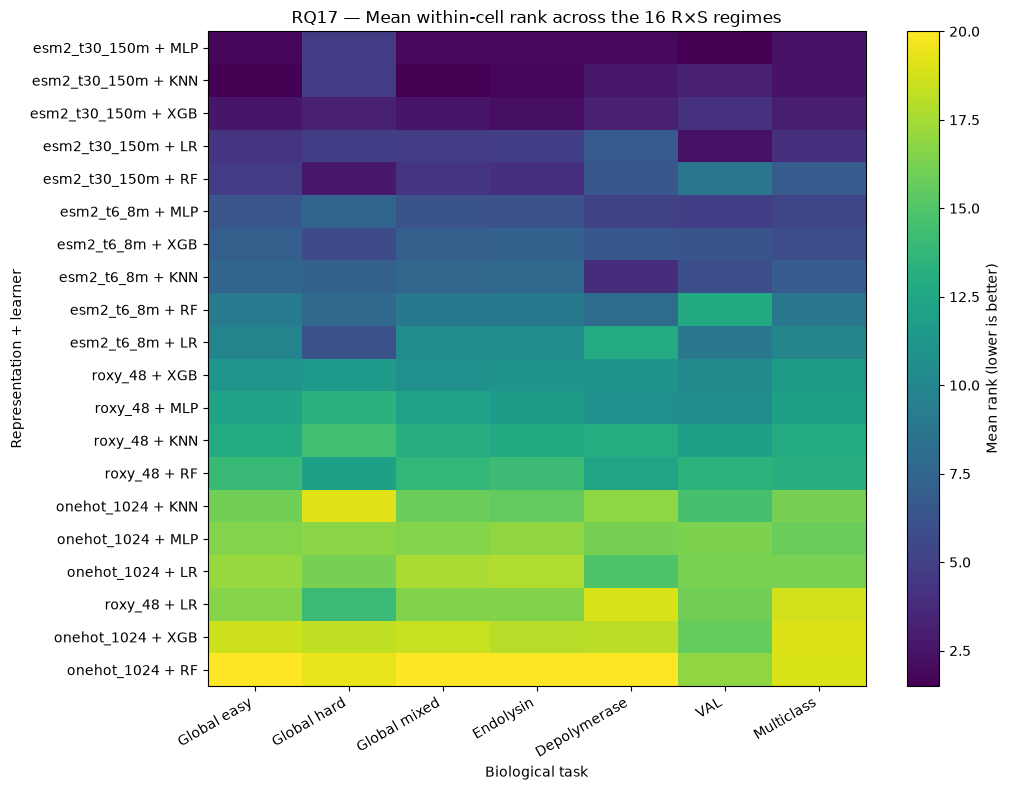

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq17_robustness_synthesis/figures/rq17_mean_rank_heatmap.png


In [11]:

# Figure 1 — strategy mean rank across tasks.
rank_pivot = (
    profile.pivot_table(
        index="strategy_id",
        columns="task",
        values="mean_rank",
        aggfunc="first",
    )
    .reindex(columns=TASKS)
)

order = (
    rank_pivot.mean(axis=1)
    .sort_values()
    .index
)
rank_pivot = rank_pivot.loc[order]

fig, ax = plt.subplots(figsize=(10.5, 8.0))
im = ax.imshow(rank_pivot.to_numpy(dtype=float), aspect="auto")
ax.set_xticks(range(len(TASKS)), [TASK_LABEL.get(t, t) for t in TASKS], rotation=30, ha="right")
ax.set_yticks(range(len(rank_pivot.index)), rank_pivot.index)
ax.set_xlabel("Biological task")
ax.set_ylabel("Representation + learner")
ax.set_title("RQ17 — Mean within-cell rank across the 16 R×S regimes")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Mean rank (lower is better)")
fig.tight_layout()

path = FIG_DIR / "rq17_mean_rank_heatmap.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


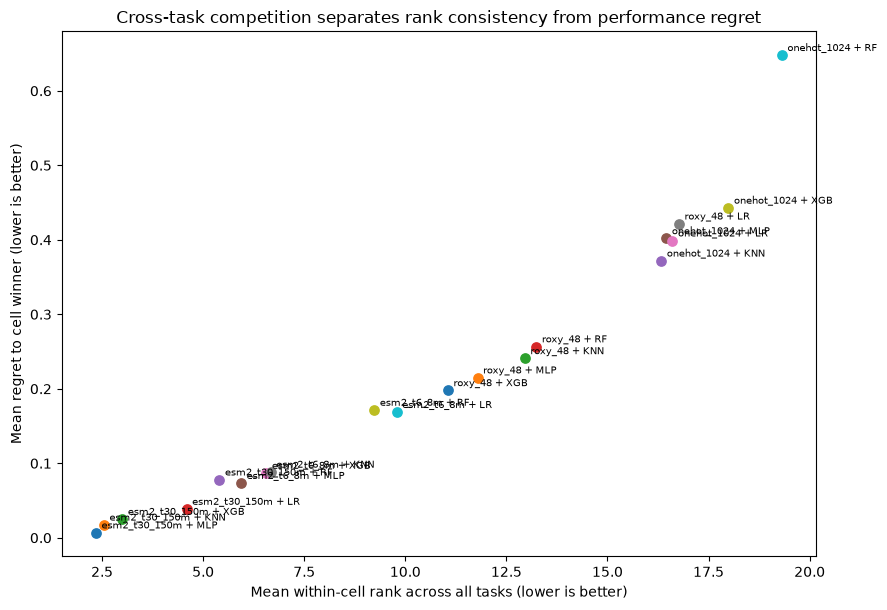

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq17_robustness_synthesis/figures/rq17_cross_task_rank_vs_regret.png


In [12]:

# Figure 2 — cross-task mean rank versus regret.
fig, ax = plt.subplots(figsize=(9.0, 6.2))

for _, row in cross_task.iterrows():
    ax.scatter(row["mean_cell_rank"], row["mean_cell_regret"], s=45)
    ax.annotate(
        row["strategy_id"],
        (row["mean_cell_rank"], row["mean_cell_regret"]),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=7,
    )

ax.set_xlabel("Mean within-cell rank across all tasks (lower is better)")
ax.set_ylabel("Mean regret to cell winner (lower is better)")
ax.set_title("Cross-task competition separates rank consistency from performance regret")
fig.tight_layout()

path = FIG_DIR / "rq17_cross_task_rank_vs_regret.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


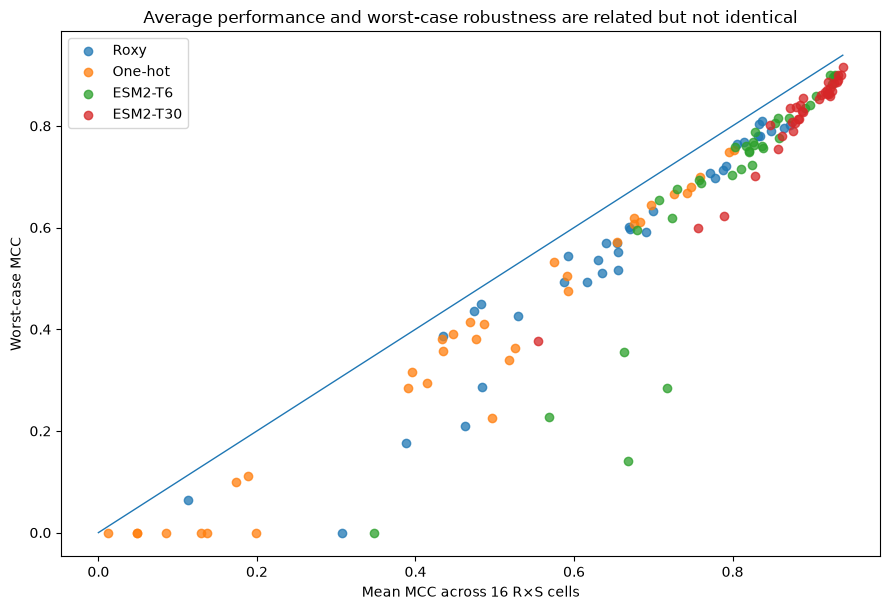

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq17_robustness_synthesis/figures/rq17_mean_vs_worst_case.png


In [13]:

# Figure 3 — performance versus robustness for every task-specific surface.
fig, ax = plt.subplots(figsize=(9.0, 6.2))

for rep in REPS:
    sub = profile[profile["representation"].eq(rep)]
    ax.scatter(
        sub["mean_mcc"],
        sub["worst_mcc"],
        label=REP_LABEL.get(rep, rep),
        alpha=0.75,
    )

lo = float(min(profile["mean_mcc"].min(), profile["worst_mcc"].min()))
hi = float(max(profile["mean_mcc"].max(), profile["worst_mcc"].max()))
ax.plot([lo, hi], [lo, hi], linewidth=1)
ax.set_xlabel("Mean MCC across 16 R×S cells")
ax.set_ylabel("Worst-case MCC")
ax.set_title("Average performance and worst-case robustness are related but not identical")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq17_mean_vs_worst_case.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


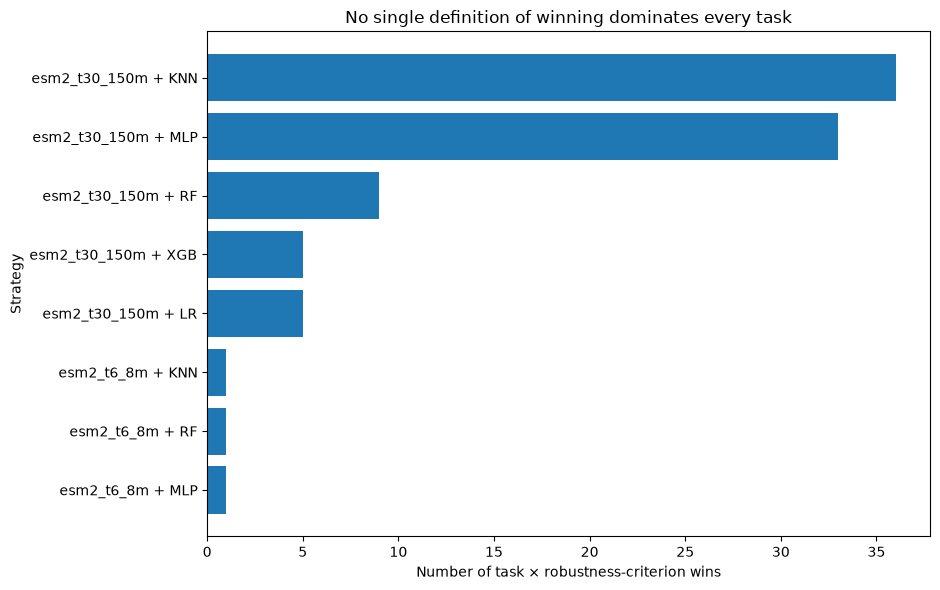

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq17_robustness_synthesis/figures/rq17_criterion_win_frequency.png


In [14]:

# Figure 4 — how concentrated are criterion wins?
top_freq = winner_frequency.head(15).sort_values("n_task_criterion_wins", ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 6.0))
ax.barh(top_freq["strategy_id"], top_freq["n_task_criterion_wins"])
ax.set_xlabel("Number of task × robustness-criterion wins")
ax.set_ylabel("Strategy")
ax.set_title("No single definition of winning dominates every task")
fig.tight_layout()

path = FIG_DIR / "rq17_criterion_win_frequency.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 11. Compact evidence summary

In [15]:

best_cross_task = cross_task.iloc[0]
most_common_winner = winner_frequency.iloc[0]

global_summary = pd.DataFrame(
    [
        {
            "n_input_rows": len(master),
            "n_task_cells": len(coverage_cells),
            "n_model_surfaces": len(profile),
            "n_unique_strategies": n_expected_strategies,
            "n_robustness_criteria_per_task": expected_criteria,
            "median_unique_winners_per_task": winner_concordance["n_unique_winning_strategies"].median(),
            "min_unique_winners_per_task": winner_concordance["n_unique_winning_strategies"].min(),
            "max_unique_winners_per_task": winner_concordance["n_unique_winning_strategies"].max(),
            "top_cross_task_strategy": best_cross_task["strategy_id"],
            "top_cross_task_mean_rank": best_cross_task["mean_cell_rank"],
            "top_cross_task_mean_regret": best_cross_task["mean_cell_regret"],
            "most_frequent_criterion_winner": most_common_winner["strategy_id"],
            "most_frequent_criterion_winner_count": most_common_winner["n_task_criterion_wins"],
        }
    ]
)

display(global_summary)

print("Cross-task top strategy:", best_cross_task["strategy_id"])
print("  mean cell rank:", round(float(best_cross_task["mean_cell_rank"]), 4))
print("  mean cell regret:", round(float(best_cross_task["mean_cell_regret"]), 4))
print("  exact-win fraction:", round(float(best_cross_task["exact_win_fraction"]), 4))
print("  near-best≤0.01 fraction:", round(float(best_cross_task["near_best_fraction_001"]), 4))
print()
print(
    "Median number of distinct winners across robustness definitions per task:",
    float(winner_concordance["n_unique_winning_strategies"].median()),
)


,n_input_rows,n_task_cells,n_model_surfaces,n_unique_strategies,n_robustness_criteria_per_task,median_unique_winners_per_task,min_unique_winners_per_task,max_unique_winners_per_task,top_cross_task_strategy,top_cross_task_mean_rank,top_cross_task_mean_regret,most_frequent_criterion_winner,most_frequent_criterion_winner_count
0,2240,112,140,20,13,3.0,2,5,esm2_t30_150m + MLP,2.348214,0.006926,esm2_t30_150m + KNN,36


Cross-task top strategy: esm2_t30_150m + MLP
  mean cell rank: 2.3482
  mean cell regret: 0.0069
  exact-win fraction: 0.3214
  near-best≤0.01 fraction: 0.7411

Median number of distinct winners across robustness definitions per task: 3.0



## 12. What RQ17 should conclude after real-data execution

RQ17 is designed to distinguish at least the following concepts:

- **best peak** — reaches the highest MCC somewhere in the R×S landscape;
- **best average** — performs best on average across all 16 cells;
- **best worst-case** — protects the lower tail of performance;
- **best rank-consistent** — remains near the top relative to competitors across cells;
- **lowest regret** — stays closest to whichever strategy wins each cell;
- **best remote-generalization** — remains strongest when `S=30`;
- **best strict-redundancy** — remains strongest when `R=30`;
- **least R/S/interaction-sensitive competitive strategy** — among genuinely competitive models, shows the smallest dependence on each upstream perturbation.

The central scientific question is whether these labels identify the same strategy. If they do not, the correct conclusion is not that the benchmark is indecisive; it is that **“winning” is operationally multidimensional**.

### Explicit exclusions

RQ17 does **not**:

- infer statistical equivalence;
- reuse bootstrap confidence intervals;
- select a deployment model;
- optimize an ensemble;
- incorporate compute into a final deployment score.

Those belong to RQ19, RQ23, RQ26 and RQ27.


## 13. Export canonical RQ17 artifacts

In [16]:

exports = {
    "rq17_cell_rankings_and_regret.tsv": cell_rankings[
        [
            "task", "R", "S", "representation", "algorithm", "strategy_id",
            PRIMARY_METRIC, "cell_best_mcc", "cell_regret", "cell_rank",
            "exact_win", "near_best_001",
        ]
    ],
    "rq17_surface_robustness_profiles.tsv": profile,
    "rq17_task_winner_matrix.tsv": winner_matrix,
    "rq17_winner_concordance.tsv": winner_concordance,
    "rq17_winner_frequency.tsv": winner_frequency,
    "rq17_cross_task_strategy_summary.tsv": cross_task,
    "rq17_representation_robustness_summary.tsv": rep_summary,
    "rq17_algorithm_robustness_summary.tsv": alg_summary,
    "rq17_global_summary.tsv": global_summary,
}

for filename, df in exports.items():
    path = RQ17_OUT / filename
    df.to_csv(path, sep="\t", index=False)
    print(f"Wrote {filename}: {len(df)} rows")

manifest = {
    "rq": "RQ17",
    "question": "what does it really mean for a model to win robustly?",
    "primary_metric": PRIMARY_METRIC,
    "competitive_mean_mcc_gap": COMPETITIVE_GAP,
    "near_best_gap": NEAR_BEST_GAP,
    "n_input_rows": int(len(master)),
    "n_task_cells": int(len(coverage_cells)),
    "n_model_surfaces": int(len(profile)),
    "n_unique_strategies": int(n_expected_strategies),
    "n_robustness_criteria_per_task": int(expected_criteria),
    "sources_used_for_sensitivity": sources_used,
    "ranking_contract": "within matched task×R×S cells only",
    "training_performed": False,
    "prediction_regeneration_performed": False,
    "bootstrap_performed": False,
    "deployment_selection_performed": False,
    "ensemble_optimization_performed": False,
}

with open(RQ17_OUT / "rq17_manifest.json", "w", encoding="utf-8") as fh:
    json.dump(manifest, fh, indent=2)

print("Wrote rq17_manifest.json")


Wrote rq17_cell_rankings_and_regret.tsv: 2240 rows
Wrote rq17_surface_robustness_profiles.tsv: 140 rows
Wrote rq17_task_winner_matrix.tsv: 91 rows
Wrote rq17_winner_concordance.tsv: 7 rows
Wrote rq17_winner_frequency.tsv: 8 rows
Wrote rq17_cross_task_strategy_summary.tsv: 20 rows
Wrote rq17_representation_robustness_summary.tsv: 4 rows
Wrote rq17_algorithm_robustness_summary.tsv: 5 rows
Wrote rq17_global_summary.tsv: 1 rows
Wrote rq17_manifest.json


## 14. Execution gates

In [17]:

required_exports = [
    "rq17_cell_rankings_and_regret.tsv",
    "rq17_surface_robustness_profiles.tsv",
    "rq17_task_winner_matrix.tsv",
    "rq17_winner_concordance.tsv",
    "rq17_winner_frequency.tsv",
    "rq17_cross_task_strategy_summary.tsv",
    "rq17_representation_robustness_summary.tsv",
    "rq17_algorithm_robustness_summary.tsv",
    "rq17_global_summary.tsv",
    "rq17_manifest.json",
]

assert len(master) == n_expected_rows
assert len(coverage_cells) == len(TASKS) * 16
assert coverage_cells["n_strategies"].eq(n_expected_strategies).all()
assert len(profile) == n_expected_surfaces
assert profile.groupby("task").size().eq(n_expected_strategies).all()
assert rank_summary.groupby("task").size().eq(n_expected_strategies).all()
assert cell_rankings.groupby(["task", "R", "S"])["cell_rank"].min().eq(1.0).all()
assert (cell_rankings["cell_regret"] >= -1e-12).all()
assert winner_matrix.groupby("task").size().eq(expected_criteria).all()
assert len(cross_task) == n_expected_strategies
assert cross_task["n_cells"].eq(len(TASKS) * 16).all()
assert profile[
    [
        "peak_mcc", "mean_mcc", "median_mcc", "worst_mcc", "surface_range",
        "win_count", "mean_rank", "worst_rank", "mean_regret",
        "R_sensitivity_abs_median", "S_sensitivity_abs_median",
        "interaction_rms",
    ]
].notna().all().all()
assert all((RQ17_OUT / f).is_file() for f in required_exports)

figure_files = sorted(p.name for p in FIG_DIR.glob("*.png"))
assert len(figure_files) >= 4, f"Expected at least 4 RQ17 figures, found {figure_files}"

print("RQ17_EXECUTION_GATES_OK")
print("Input rows:", len(master))
print("Matched task×R×S cells:", len(coverage_cells))
print("Complete model surfaces:", len(profile))
print("Unique representation×learner strategies:", len(cross_task))
print("Robustness criteria per task:", expected_criteria)
print("Exports:", len(required_exports))
print("Figures:", figure_files)
print()
print(
    "Interpretation status: execution gates passed. "
    "Real-data scientific PASS should only be assigned after the executed notebook and outputs are inspected."
)


RQ17_EXECUTION_GATES_OK
Input rows: 2240
Matched task×R×S cells: 112
Complete model surfaces: 140
Unique representation×learner strategies: 20
Robustness criteria per task: 13
Exports: 10
Figures: ['rq17_criterion_win_frequency.png', 'rq17_cross_task_rank_vs_regret.png', 'rq17_mean_rank_heatmap.png', 'rq17_mean_vs_worst_case.png']

Interpretation status: execution gates passed. Real-data scientific PASS should only be assigned after the executed notebook and outputs are inspected.
